# α-Synuclein C-terminal trajectory: Cα-position tICA
Analyze the protein-only trajectory using aligned Cα Cartesian coordinates. This notebook uses all stored frames; the input DCD already has stride 100.

Run cells in order in Colab. The input cell automatically downloads the PDB and DCD (about 19 MB total) from the class repository. This is an exploratory analysis of residues 121–140, not a validated kinetic model.

In [1]:
import importlib.util
if importlib.util.find_spec("MDAnalysis") is None:
    %pip -q install MDAnalysis
from pathlib import Path
import os, json
import numpy as np
import MDAnalysis as mda
from scipy.linalg import eigh
import matplotlib.pyplot as plt

/Users/paulrobustelli/Documents/Codex/2026-11-11/referenced-chatgpt-conversation-this-is-an/work/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Inputs and time calibration
The supplied trajectory covers approximately **200 μs**. We use Δt = 200 μs / N stored frames, about 36 ns/frame for 5,555 frames. If 200 μs is the exact first-to-last span, use N−1 instead. The stride is already included in N: do not multiply Δt by 100 again. Confirm the physical duration against simulation records before interpreting timescales.

In [2]:
# Download the published inputs unless local files were supplied.
from urllib.request import urlretrieve
import hashlib

PDB = Path(os.environ.get("ASYN_PDB", "asyn_Cterm_apo.proteinonly.pdb"))
DCD = Path(os.environ.get("ASYN_DCD", "asyn_Cterm_apo.proteinonly.s100.dcd"))
DATA_URL = "https://raw.githubusercontent.com/paulrobustelli/CSMP_150_2026/main/data/asyn/"
EXPECTED_SHA256 = {'asyn_Cterm_apo.proteinonly.s100.dcd': '46ee4d6f27ba2fb4ff3e37f168526bd049b0a2551ef4c0f659d5e28203587467', 'asyn_Cterm_apo.proteinonly.pdb': '37dc62f1aa4acb8880d81e6114881447780e607cc969f2bdac527119237b8009'}
for path, override in ((PDB, "ASYN_PDB"), (DCD, "ASYN_DCD")):
    if not path.is_file():
        if override in os.environ:
            raise FileNotFoundError(f"Local input does not exist: {path}")
        print(f"Downloading {path.name} ...")
        urlretrieve(DATA_URL + path.name, path)
    # Verify that the supplied class files downloaded without corruption.
    if override not in os.environ:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if digest != EXPECTED_SHA256[path.name]:
            raise ValueError(f"Checksum mismatch for {path}; delete it and rerun this cell.")

DURATION_US = 200.0
LAG_FRAMES = 28
out = Path("asyn_tica_output")
out.mkdir(exist_ok=True)


## 2. Remove rigid-body motion
Select Cα atoms, check adjacent distances, remove translation and align every frame to an iteratively updated mean structure. The resulting features are the 3 Cartesian coordinates of each aligned Cα. For an intrinsically disordered peptide, the chosen alignment affects the result. The distance check detects gross chain breaks; it is not a general periodic-boundary correction.

In [3]:
u = mda.Universe(str(PDB), str(DCD))
ca=u.select_atoms('name CA')
xyz=np.array([ca.positions.copy() for ts in u.trajectory],dtype=float)
# Check chain continuity before aligning Cartesian coordinates.
dist=np.linalg.norm(np.diff(xyz,axis=1),axis=2)
print('Adjacent CA distances range (A)',dist.min(),dist.max())
if dist.max()>8: raise ValueError('Broken chain / periodic wrapping: make protein whole before alignment.')
xyz-=xyz.mean(axis=1,keepdims=True)
def align(a,ref):
    U,s,V=np.linalg.svd(np.einsum('nki,kj->nij',a,ref))
    d=np.linalg.det(U@V)
    U[:,:,-1]*=d[:,None]
    return a@(U@V)
# Iterative common mean reference removes global translation and rotation.
ref=xyz[0].copy()
for it in range(30):
    aligned=align(xyz,ref)
    new=aligned.mean(axis=0)
    if np.sqrt(np.mean((new-ref)**2))<1e-7: break
    ref=new
X=aligned.reshape(len(xyz),-1)
dt=DURATION_US/len(X) # microseconds; approximate duration supplied by user

print(f"{len(X)} frames, {len(ca)} Cα atoms; Δt = {dt*1000:.6f} ns")

Adjacent CA distances range (A) 3.564552264720016 4.111080288175443
5555 frames, 20 Cα atoms; Δt = 36.003600 ns


/Users/paulrobustelli/Documents/Codex/2026-11-11/referenced-chatgpt-conversation-this-is-an/work/venv/lib/python3.9/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


## 3. Fit reversible tICA
Construct centered, lag-separated endpoint matrices $A$ and $B$ using their pooled mean. With $n$ pairs:
$$C_0=\frac{A^TA+B^TB}{2n},\qquad C_\tau=\frac{A^TB+B^TA}{2n}.$$
Solve $C_\tau w_i=\lambda_i C_0w_i$ with $w_i^TC_0w_j=\delta_{ij}$. Whitening retains covariance directions above a relative threshold of $10^{-8}$, avoiding division by near-zero variance.

The projected trajectory is $z_i(t)=(X_t-\bar X)^Tw_i$. Symmetrization imposes the reversible estimator; it does not establish that the sampled trajectory is equilibrated. Eigenvector signs are arbitrary.

In [4]:
def fit(lag):
    a,b=X[:-lag],X[lag:]
    mean=(a.mean(0)+b.mean(0))/2
    a,b=a-mean,b-mean
    C0=(a.T@a+b.T@b)/(2*len(a))
    Ct=(a.T@b+b.T@a)/(2*len(a))
    d,v=eigh(C0)
    keep=d>d.max()*1e-8
    W=v[:,keep]/np.sqrt(d[keep])
    ev,vec=eigh(W.T@Ct@W)
    ev,vec=ev[::-1],vec[:,::-1]
    weights=W@vec
    for i in range(weights.shape[1]):
        if weights[np.argmax(abs(weights[:,i])),i]<0: weights[:,i]*=-1
    assert np.max(abs(weights.T@C0@weights-np.eye(len(ev))))<1e-7
    residual=np.linalg.norm(Ct@weights-C0@weights*ev)/np.linalg.norm(Ct@weights)
    return ev,weights,(X-mean)@weights,C0,Ct,mean,residual
lag=LAG_FRAMES
ev,w,z,C0,Ct,mean,res=fit(lag)

assert res < 1e-6
assert np.all(np.abs(ev) <= 1 + 1e-8)
print("Leading eigenvalues:", ev[:5])
print("Eigenpair relative residual:", res)

Leading eigenvalues: [0.63840411 0.25407017 0.19815031 0.13750721 0.12123997]
Eigenpair relative residual: 6.572947486339455e-15


## 4. Project the full trajectory
The first three tICs are ordered by decreasing eigenvalue. Unit variance refers to the paired covariance used in fitting, not necessarily the variance over every frame.

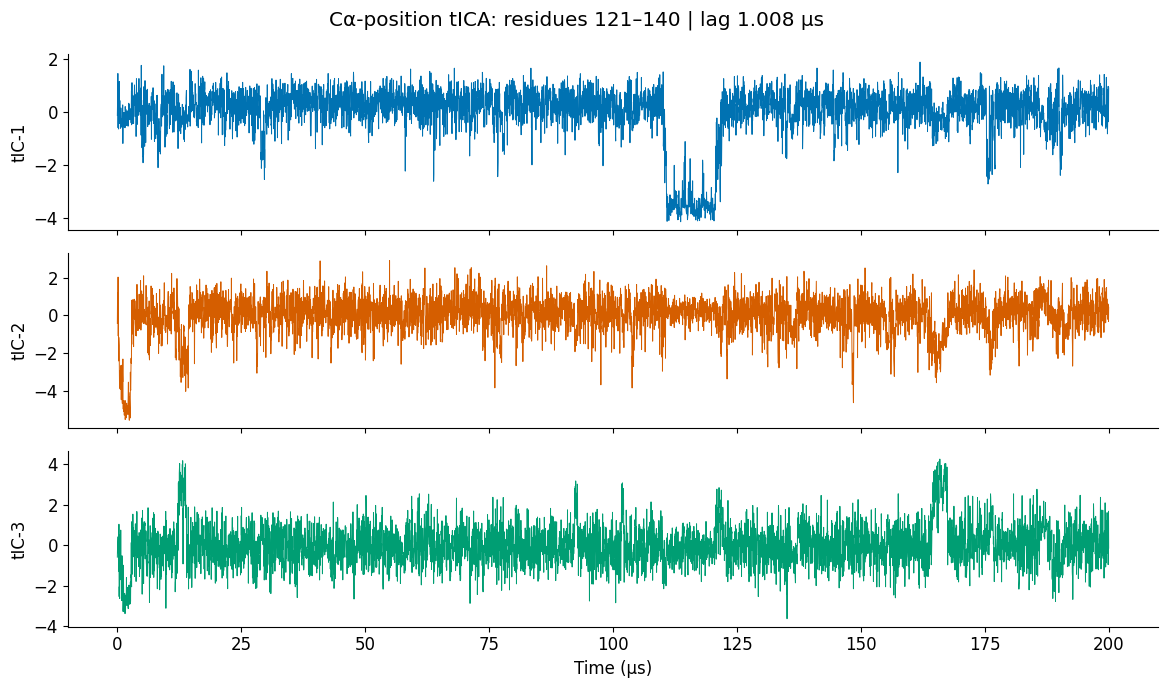

In [5]:
plt.rcParams.update({'font.size':12,'axes.spines.top':False,'axes.spines.right':False})
fig,axs=plt.subplots(3,1,figsize=(12,7),sharex=True)
for i,ax in enumerate(axs):
    ax.plot(np.arange(len(z))*dt,z[:,i],lw=.7,color=['#0072B2','#D55E00','#009E73'][i]); ax.set_ylabel(f'tIC-{i+1}')
axs[-1].set_xlabel('Time (µs)')
fig.suptitle(f'Cα-position tICA: residues {ca.resids[0]}–{ca.resids[-1]} | lag {lag*dt:.3f} µs')
fig.tight_layout();fig.savefig(out/'tica_traces.png',dpi=200);plt.show(); plt.close(fig)


## 5. Projected free energy and coordinate weights
Estimate $F/k_BT=-\ln(P/P_{\max})$ from a 2D histogram of tIC-1 and tIC-2. Empty bins are masked; the color range is capped at 6. This is a sampled projected distribution, not an independent potential-energy surface. Weight magnitudes show each residue’s contribution to the linear coordinate, not a probability or displacement amplitude.

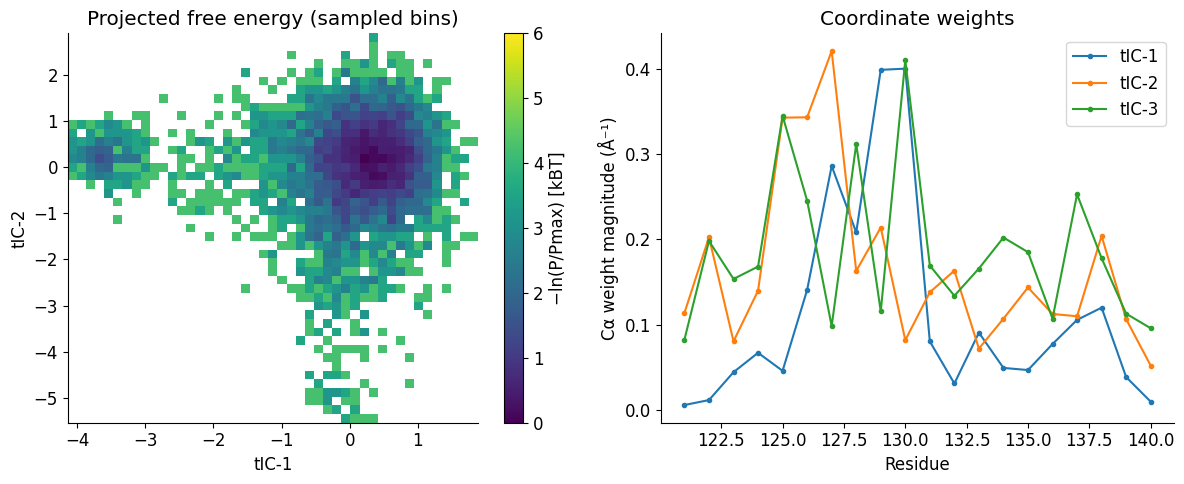

In [6]:
fig,axs=plt.subplots(1,2,figsize=(12,5))
H,xe,ye=np.histogram2d(z[:,0],z[:,1],bins=45)
F=np.full_like(H,np.nan); good=H>0;F[good]=-np.log(H[good]/H.max())
im=axs[0].pcolormesh(xe,ye,F.T,cmap='viridis',vmin=0,vmax=6,rasterized=True)
fig.colorbar(im,ax=axs[0],label='−ln(P/Pmax) [kBT]');axs[0].set(xlabel='tIC-1',ylabel='tIC-2',title='Projected free energy (sampled bins)')
for i in range(3):
    norm=np.linalg.norm(w[:,i].reshape(-1,3),axis=1)
    axs[1].plot(ca.resids,norm,marker='o',ms=3,label=f'tIC-{i+1}')
axs[1].set(xlabel='Residue',ylabel='Cα weight magnitude (Å⁻¹)',title='Coordinate weights');axs[1].legend()
fig.tight_layout();fig.savefig(out/'tica_fes_weights.png',dpi=200);plt.show(); plt.close(fig)


## 6. Autocorrelation and implied relaxation times
For each fixed projection, estimate its normalized autocorrelation as a function of separation. Separately, refit tICA at each lag and calculate
$$t_i(\tau)=-\frac{\tau}{\ln\lambda_i(\tau)},\qquad 0<\lambda_i<1.$$
The empirical autocorrelation uses a global trajectory mean and variance, so it can differ slightly from the paired estimator’s eigenvalue. The lag scan orders modes by eigenvalue at each lag; it does not track mode identity through crossings. A plateau and sampling checks are needed before claiming converged relaxation times.

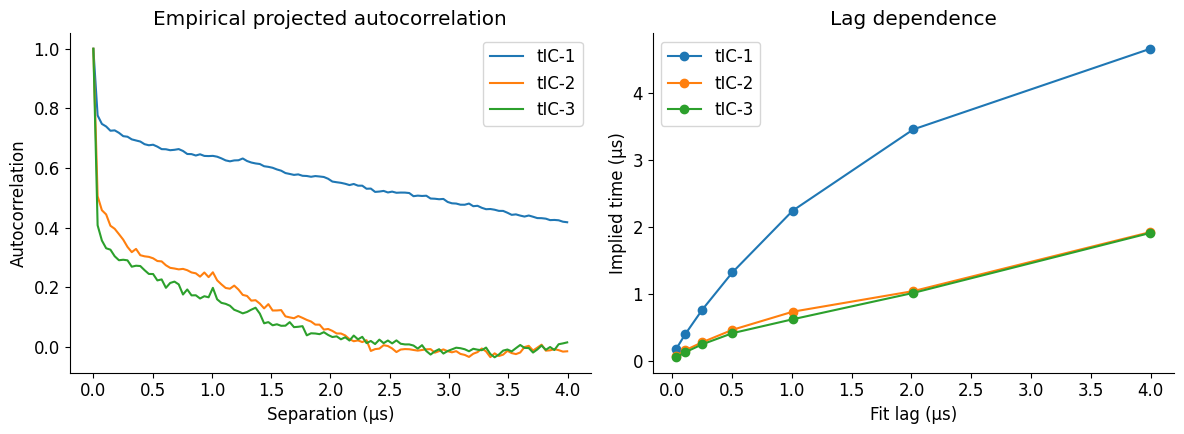

In [7]:
lags=[1,3,7,14,28,56,111]
rows=[]
for l in lags:
    e,*_=fit(l)
    times=np.where((e[:5]>0)&(e[:5]<1),-l*dt/np.log(np.clip(e[:5],1e-15,1-1e-15)),np.nan)
    rows.append([l,l*dt,*e[:5],*times])
rows=np.array(rows)
np.savetxt(out/'lag_scan.csv',rows,delimiter=',',header='lag_frames,lag_us,'+','.join(f'lambda{i}' for i in range(1,6))+','+','.join(f'time{i}_us' for i in range(1,6)),comments='')
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for i in range(3):
    centered=z[:,i]-z[:,i].mean()
    ac=np.array([np.mean(centered[:-l]*centered[l:])/np.mean(centered**2) if l else 1 for l in range(112)])
    axs[0].plot(np.arange(112)*dt,ac,label=f'tIC-{i+1}')
    axs[1].plot(rows[:,1],rows[:,7+i],'-o',label=f'tIC-{i+1}')
axs[0].set(xlabel='Separation (µs)',ylabel='Autocorrelation',title='Empirical projected autocorrelation');axs[0].legend()
axs[1].set(xlabel='Fit lag (µs)',ylabel='Implied time (µs)',title='Lag dependence');axs[1].legend()
fig.tight_layout();fig.savefig(out/'tica_lag_check.png',dpi=200);plt.show(); plt.close(fig)


## 7. Save results
Save projections, eigenvectors, covariance matrices, aligned Cα coordinates, figures and a numerical summary in `asyn_tica_output`. Download these files from the Colab Files sidebar.

In [8]:
np.savez(out/'tica_results.npz',scores=z,weights=w,eigenvalues=ev,C0=C0,Ctau=Ct,mean=mean,aligned_ca=aligned,resids=ca.resids,lag_frames=lag,frame_spacing_us=dt)
np.savetxt(out/'tica_projections.csv',np.column_stack([np.arange(len(z))*dt,z[:,:5]]),delimiter=',',header='time_us,tIC1,tIC2,tIC3,tIC4,tIC5',comments='')
report={'frames':len(X),'ca_atoms':len(ca),'residues':ca.resids.tolist(),'frame_spacing_ns':dt*1000,'lag_frames':lag,'lag_us':lag*dt,'leading_eigenvalues':ev[:5].tolist(),'implied_times_us':(-lag*dt/np.log(ev[:5])).tolist(),'eigenpair_relative_residual':res,'max_adjacent_ca_distance_A':float(dist.max())}
(out/'summary.json').write_text(json.dumps(report,indent=2))

print(json.dumps(report, indent=2))

{
  "frames": 5555,
  "ca_atoms": 20,
  "residues": [
    121,
    122,
    123,
    124,
    125,
    126,
    127,
    128,
    129,
    130,
    131,
    132,
    133,
    134,
    135,
    136,
    137,
    138,
    139,
    140
  ],
  "frame_spacing_ns": 36.003600360036,
  "lag_frames": 28,
  "lag_us": 1.008100810081008,
  "leading_eigenvalues": [
    0.6384041068481745,
    0.2540701651794138,
    0.19815031043649478,
    0.13750721305963515,
    0.1212399690871645
  ],
  "implied_times_us": [
    2.2462950098756918,
    0.7357622371571467,
    0.6227729073458762,
    0.5080951204740578,
    0.47777663607007015
  ],
  "eigenpair_relative_residual": 6.572947486339455e-15,
  "max_adjacent_ca_distance_A": 4.111080288175443
}
